# Experiment 3: one scale for every way of picking the week

Experiment 1 scored the drift rule by how many of its asks landed on a week with a high PHQ-2. Experiment 1b scored models by AUC. This notebook shows Experiment 3, which gives every method the same number of asks and scores them all the way Experiment 1 did, then repeats the numbers by gender and race.

It reads `results/exp3/results.json`, written by `experiments/exp3_asking.py`, so it runs without the datasets. Every number is an aggregate over at least 20 students.

*This is a prototype analysis and is not medical advice. It was written with Claude (Anthropic).*

In [1]:
import json
from pathlib import Path

import pandas as pd
from IPython.display import Image, Markdown, display

REPO = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()
res = json.loads((REPO / "results" / "exp3" / "results.json").read_text())
labels = {m["key"]: m["label"] for m in res["methods"]}
labels["drift_rule"] = "Drift rule (Experiment 1)"
pd.set_option("display.max_colwidth", 90)
pd.set_option("display.width", 200)

def pc(x, nd=1):
    return f"{100 * x:.{nd}f}%"

display(Markdown("**Short answer.** " + res["headline"]))
pd.Series(res["data"]).to_frame("value")

/opt/anaconda3/lib/python3.13/site-packages/pandas/core/computation/expressions.py:23: UserWarning: Pandas requires version '2.10.2' or newer of 'numexpr' (version '2.10.1' currently installed).
  from pandas.core.computation.check import NUMEXPR_INSTALLED


**Short answer.** At 12 asks per student-year, 24% of the asks chosen from one check-in landed on a week with a high PHQ-2, against 13% for a fixed calendar and 18% for a phone model; random weeks from the same student and quarter reached 23%, so nearly all of the gain comes from finding which students and which term to ask in, and the choice of week adds about one point.

,value
students,213.000000
monitored_weeks,22688.000000
labelled_weeks,16886.000000
base_rate,0.128568
share_weeks_with_a_checkin_last_week,0.801657
share_weeks_with_an_earlier_answer,1.000000


## 1. The methods

Each method gives every monitored week a score, and the highest-scoring weeks get the asks. The last column says what the method needs from the student before it can decide. The two reference rows need a PHQ-2 answer nearly every week, which an app held to 12 asks a year would not have.

In [2]:
pd.DataFrame(res["methods"])[["label", "uses", "decides", "needs"]]

,label,uses,decides,needs
0,Phone model,"Phone data from the week itself (every daily measure, as in Experiment 1b's same-week ...",end of the week,Nothing from the student
1,One check-in from last week,"The latest mood picture, stress and time-with-others answer from the previous calendar...",Monday,A short check-in each week
2,Check-in history,"Last week's check-ins, the average of every earlier check-in, and the change between them",Monday,A short check-in each week
3,Check-ins plus earlier PHQ-2 answers (reference),"Check-in history plus the student's earlier PHQ-2 answers, all dated before Monday",Monday,A PHQ-2 answer nearly every week (reference only)
4,"Follow-up rule, no model (reference)",The most recent PHQ-2 answer before Monday: ask again where the last answer was highest,Monday,A PHQ-2 answer nearly every week (reference only)


## 2. Hit rate at the same number of asks

Hit rate is the share of asks that landed on a week with a PHQ-2 of 3 or more. "Matched random" is random weeks that keep the method's number of asks for each student in each calendar quarter. When a method's hit rate is close to its matched random, the method is finding the right students and terms, and adds little by choosing the week.

In [3]:
def budget_table(key):
    blk = res["by_budget"][key]
    rows = []
    for k, r in blk["methods"].items():
        rows.append({
            "method": labels[k],
            "hit rate": pc(r["hit_rate"]),
            "fixed calendar": pc(r["calendar_hit_rate"]),
            "minus calendar (95% interval)": f"{100 * r['minus_calendar']:+.1f} ({100 * r['minus_calendar_ci'][0]:.1f} to {100 * r['minus_calendar_ci'][1]:.1f})",
            "matched random": pc(r["matched_random_hit_rate"]),
            "high weeks missed": f"{r['high_weeks_missed']:,} of {r['high_weeks']:,}",
            "false alarms": f"{r['false_alarms']:,}",
            "low periods reached": pc(r["share_low_periods_reached"], 0),
            "low periods reached, calendar": pc(r["calendar_share_low_periods_reached"], 0),
        })
    display(Markdown(f"**{blk['label']}: {blk['asks_per_student_year']:.1f} asks per student-year**"))
    display(pd.DataFrame(rows))

for key in res["by_budget"]:
    budget_table(key)

**the drift rule's own budget: 21.4 asks per student-year**

,method,hit rate,fixed calendar,minus calendar (95% interval),matched random,high weeks missed,false alarms,low periods reached,"low periods reached, calendar"
0,Drift rule (Experiment 1),14.6%,12.9%,+1.8 (0.0 to 3.7),14.9%,"1,164 of 2,171","5,869",55%,88%
1,Phone model,15.7%,12.9%,+2.9 (0.7 to 4.9),15.7%,"1,120 of 2,171","5,623",68%,88%
2,One check-in from last week,20.6%,12.9%,+7.7 (5.6 to 9.9),20.1%,"853 of 2,171","5,095",86%,88%
3,Check-in history,23.8%,12.9%,+11.0 (7.7 to 14.3),23.9%,"580 of 2,171","5,083",82%,88%
4,Check-ins plus earlier PHQ-2 answers (reference),30.2%,12.9%,+17.3 (14.5 to 20.3),29.5%,"189 of 2,171","4,588",98%,88%
5,"Follow-up rule, no model (reference)",28.9%,12.9%,+16.0 (13.2 to 18.5),28.1%,"236 of 2,171","4,758",99%,88%


**12 asks a year (monthly): 12.0 asks per student-year**

,method,hit rate,fixed calendar,minus calendar (95% interval),matched random,high weeks missed,false alarms,low periods reached,"low periods reached, calendar"
0,Phone model,18.3%,12.9%,+5.4 (2.5 to 8.6),17.8%,"1,501 of 2,171","2,990",49%,61%
1,One check-in from last week,23.5%,12.9%,+10.6 (7.4 to 14.1),22.6%,"1,227 of 2,171","3,071",74%,61%
2,Check-in history,31.6%,12.9%,+18.8 (13.3 to 24.2),31.9%,"981 of 2,171","2,573",65%,61%
3,Check-ins plus earlier PHQ-2 answers (reference),45.2%,12.9%,+32.4 (27.5 to 37.2),44.4%,"541 of 2,171","1,975",88%,61%
4,"Follow-up rule, no model (reference)",41.8%,12.9%,+29.0 (24.0 to 33.0),40.8%,"616 of 2,171","2,163",95%,61%


**6 asks a year (every two months): 6.0 asks per student-year**

,method,hit rate,fixed calendar,minus calendar (95% interval),matched random,high weeks missed,false alarms,low periods reached,"low periods reached, calendar"
0,Phone model,20.5%,12.9%,+7.6 (3.0 to 12.3),20.1%,"1,801 of 2,171","1,433",28%,34%
1,One check-in from last week,28.5%,12.9%,+15.6 (10.0 to 21.5),27.8%,"1,598 of 2,171","1,437",52%,34%
2,Check-in history,40.0%,12.9%,+27.1 (19.2 to 35.6),39.4%,"1,409 of 2,171","1,142",48%,34%
3,Check-ins plus earlier PHQ-2 answers (reference),60.2%,12.9%,+47.3 (39.9 to 55.1),59.4%,"1,048 of 2,171",742,66%,34%
4,"Follow-up rule, no model (reference)",62.8%,12.9%,+49.9 (44.0 to 54.7),60.8%,"1,012 of 2,171",687,85%,34%


## 3. The chart

The same numbers at 12 asks a year. The dark tick on each bar is the matched random hit rate, and the dashed line is the fixed calendar.

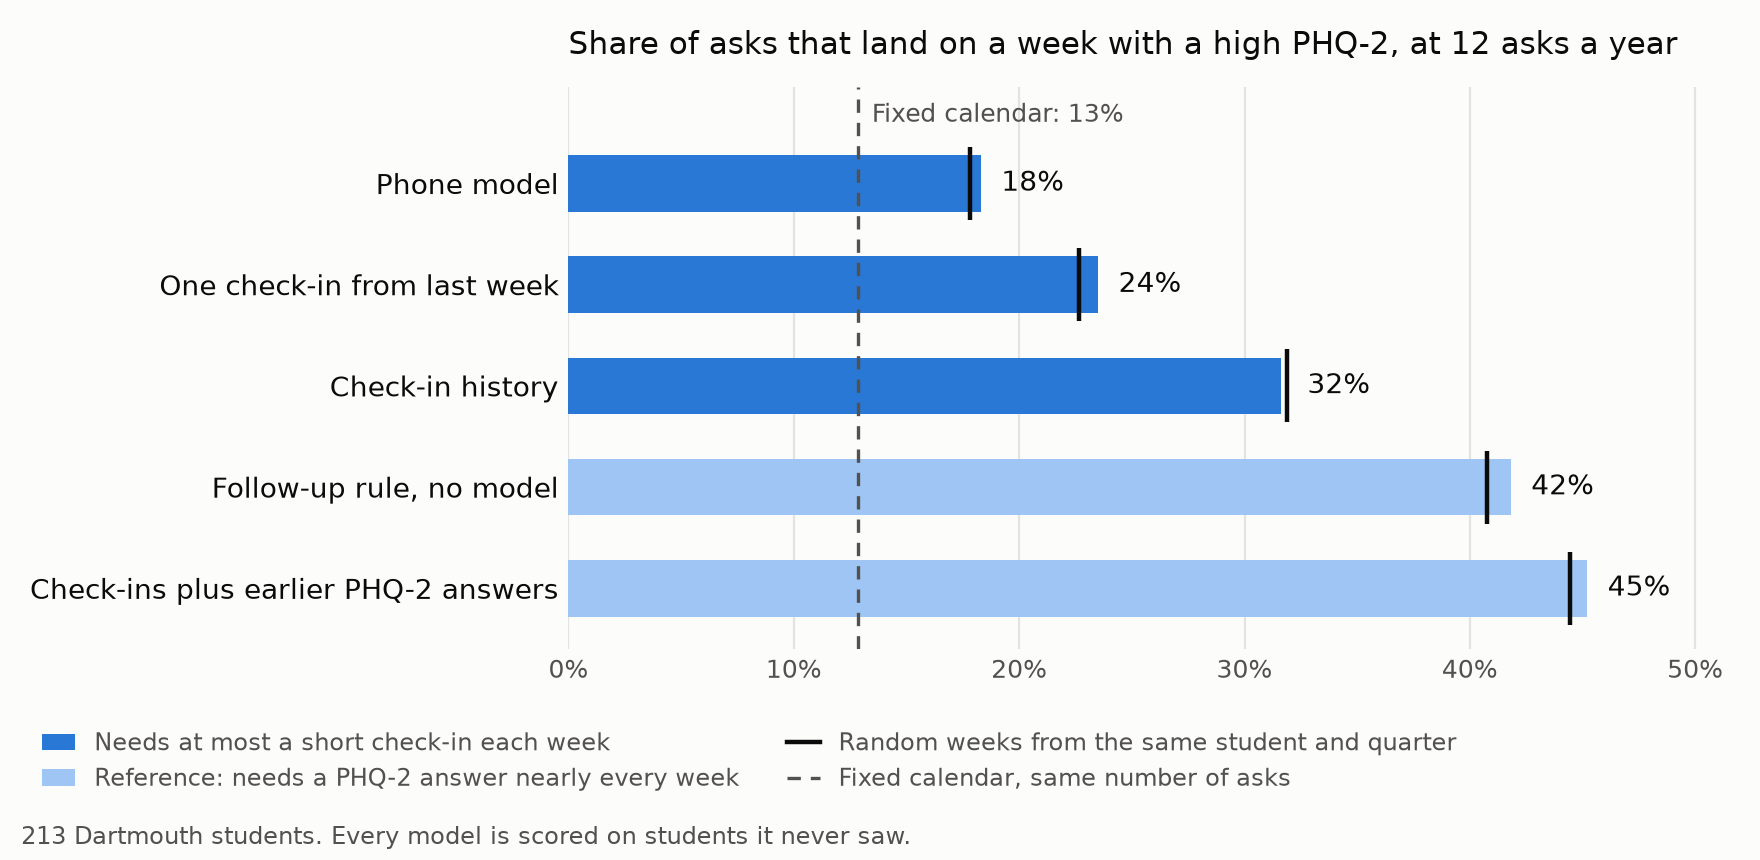

In [4]:
Image(filename=str(REPO / "results" / "exp3" / "hit_rates.png"), width=820)

## 4. How well each score ranks weeks

AUC on all labelled monitored weeks, from models that never saw the student. Within-student AUC compares only weeks of the same student, so it shows whether a score can tell a student's bad weeks from their good ones.

In [5]:
pd.DataFrame([
    {"method": labels[k], "AUC": round(a["auc"], 3),
     "95% interval": f"{a['auc_ci'][0]:.2f} to {a['auc_ci'][1]:.2f}",
     "within-student AUC": round(a["within_student_auc"], 3)}
    for k, a in res["auc"].items()])

,method,AUC,95% interval,within-student AUC
0,Phone model,0.571,0.51 to 0.63,0.572
1,One check-in from last week,0.690,0.66 to 0.72,0.610
2,Check-in history,0.781,0.74 to 0.82,0.635
3,Check-ins plus earlier PHQ-2 answers (reference),0.899,0.88 to 0.92,0.720
4,"Follow-up rule, no model (reference)",0.877,0.85 to 0.90,0.739


## 5. Groups

The hackathon asks whether a model works equally well across groups. The study records self-reported gender and race. Groups with fewer than 20 students are not shown, and the smaller race groups are pooled into one row. The tone model in Experiment 2 cannot be checked this way, because GoEmotions records nothing about who wrote each comment.

In [6]:
def group_table(dim):
    rows = []
    for name, g in res["by_group"][dim].items():
        dr, c = g["drift_rule"], g["checkin_one_monthly"]
        a = g["auc"]
        rows.append({
            "group": name, "students": g["students"], "labelled weeks": g["labelled_weeks"],
            "base rate": pc(g["base_rate"]),
            "drift rule vs calendar vs matched random": f"{pc(dr['hit_rate'])} / {pc(dr['calendar_hit_rate'])} / {pc(dr['matched_random_hit_rate'])}",
            "phone model AUC": f"{a['phone']['auc']:.2f} ({a['phone']['auc_ci'][0]:.2f} to {a['phone']['auc_ci'][1]:.2f})",
            "one check-in AUC": f"{a['checkin_one']['auc']:.2f} ({a['checkin_one']['auc_ci'][0]:.2f} to {a['checkin_one']['auc_ci'][1]:.2f})",
            "one check-in at 12 asks: hit rate vs calendar": f"{pc(c['hit_rate'])} / {pc(c['calendar_hit_rate'])}",
            "asks per student-year given": round(c["asks_per_student_year"], 1),
        })
    return pd.DataFrame(rows)

display(Markdown("**By gender**"))
display(group_table("gender"))
display(Markdown("**By race**"))
display(group_table("race"))
print("Not shown:", res["groups_not_shown"])

**By gender**

,group,students,labelled weeks,base rate,drift rule vs calendar vs matched random,phone model AUC,one check-in AUC,one check-in at 12 asks: hit rate vs calendar,asks per student-year given
0,Women,142,11613,11.8%,13.1% / 11.8% / 13.5%,0.57 (0.51 to 0.64),0.66 (0.62 to 0.69),19.6% / 11.8%,12.4
1,Men,68,5064,15.3%,17.5% / 15.3% / 17.6%,0.56 (0.43 to 0.67),0.75 (0.69 to 0.81),33.5% / 15.2%,11.2


**By race**

,group,students,labelled weeks,base rate,drift rule vs calendar vs matched random,phone model AUC,one check-in AUC,one check-in at 12 asks: hit rate vs calendar,asks per student-year given
0,Asian,51,3922,11.5%,12.4% / 11.4% / 12.9%,0.58 (0.45 to 0.69),0.69 (0.63 to 0.74),20.8% / 11.5%,12.8
1,White,133,10596,14.1%,17.0% / 14.1% / 17.1%,0.56 (0.49 to 0.63),0.70 (0.66 to 0.75),25.9% / 14.1%,12.0
2,All other groups together,27,2309,9.0%,8.6% / 9.0% / 8.8%,0.60 (0.44 to 0.71),0.63 (0.52 to 0.68),14.5% / 9.0%,10.6


Not shown: {'gender': 3, 'race': 2}


## 6. Caveats

In [7]:
display(Markdown("\n".join(f"- {c}" for c in res["caveats"])))

- These are Dartmouth college students from 2017 to 2022. Steady is meant for high school students.
- The label is a weekly PHQ-2 answered on the phone. It is a screening score, and a doctor makes the diagnosis.
- In this study the check-in questions came in the same survey as the PHQ-2. We cannot tell whether students would answer a short check-in more often than two screening questions.
- 80% of monitored weeks had a check-in in the week before. The other weeks are scored from a missing-value flag.
- The two reference rows use the student's earlier PHQ-2 answers, and 100% of monitored weeks had one because the study asked every week. An app held to 12 asks a year would not have those answers, so these rows show how long high answers last and are not a design.
- The asks are the highest-scoring weeks among students the model never saw. A real app would have to set its threshold in advance, so its number of asks would vary from the budget.
- The phone model sees the week itself, up to its last day. The check-in models and the follow-up rule only see answers from before Monday, so the comparison favours the phone model.
- The group rows describe how each method behaved in this sample. Men and the smaller race groups have few students, so their intervals are wide.
- Gender and race are self-reported in the study's own categories. Groups with fewer than 20 students are not shown.